<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5_ap_slam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio V, apêndice: SLAM por grafo de poses

## Um robô dá uma volta, reconhece o lugar de onde partiu, e corrige o caminho inteiro de uma vez

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Anterior:** [X5_dualcomplexos.ipynb](X5_dualcomplexos.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5_dualcomplexos.ipynb))

**O problema.** Um robô percorre um quadrado de 10 m de lado, contando com a odometria: a cada passo, ele mede a pose relativa entre onde estava e onde está (um dual-complexo), com ruído. Os erros se acumulam, e, no fim da volta, o robô acha que está longe do ponto de partida (nesta simulação, a 84 cm, e virado de 8°). Mas ele **reconhece** o lugar (o ICP do notebook V(b), alinhando o *scan* final com o inicial) e mede, com boa precisão, a pose relativa entre a última e a primeira pose: um **fechamento de laço**.

**O grafo.** Cada pose do caminho é um nó; cada medida de pose relativa (odometria ou fechamento de laço) é uma aresta, com a sua incerteza. Corrigir o caminho é encontrar as poses que melhor concordam com todas as arestas ao mesmo tempo:

$$\min_{q_1,\dots,q_N}\ \sum_{(i,j)}\mathbf r_{ij}^\top\,\boldsymbol\Omega_{ij}\,\mathbf r_{ij},\qquad\mathbf r_{ij}=\mathrm{Log}\big(Z_{ij}^{-1}\,q_i^{-1}q_j\big),$$

com $Z_{ij}$ a pose relativa medida e $\boldsymbol\Omega_{ij}$ a inversa da sua covariância. O resíduo é o $\boldsymbol\boxminus$ do domínio: o quanto a pose relativa prevista difere da medida, no espaço tangente.

**O método.** Gauss–Newton **no grupo** (notebook I(b), seção 5, com $\boxplus$ no lugar de $+$): linearizar os resíduos em torno das poses atuais, com perturbações $q_k\leftarrow q_k\,\mathrm{Exp}(\delta_k)$, resolver o sistema linear para todos os $\delta_k$ juntos, aplicar e repetir. A primeira pose fica fixa (senão, o grafo inteiro poderia girar e transladar sem mudar nenhum resíduo). É o que bibliotecas como g2o, GTSAM e Ceres fazem, com matrizes esparsas e milhares de poses. Aqui, com 41 poses, uma matriz densa basta, e o jacobiano sai por diferenças finitas sobre o $\boxplus$.

É o primo, em lote, do filtro de Kalman: em vez de corrigir só a pose atual, corrige o **passado inteiro** quando chega uma informação nova.

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

rng = np.random.default_rng(54)

def wrap(a):
    return np.pi - (np.pi - np.asarray(a, float)) % (2 * np.pi)

def sinc(x):
    """sen(x)/x, sem perder dígitos perto de 0 (np.sinc usa sen(πx)/(πx))."""
    return np.sinc(np.asarray(x, float) / np.pi)

class DC:
    """Número dual-complexo q = a + b·ε, com a = a0 + i·a1 e b = b0 + i·b1, e a regra z·ε = ε·z̄.
    Guardado como quatro reais (a0, a1, b0, b1), que podem ser floats, Fractions ou números duais."""
    def __init__(self, a0, a1, b0, b1):
        self.a0, self.a1, self.b0, self.b1 = a0, a1, b0, b1
    def __mul__(self, o):
        if not isinstance(o, DC):                       # número real vezes dual-complexo
            return DC(self.a0 * o, self.a1 * o, self.b0 * o, self.b1 * o)
        # a = a1·a2 ;  b = a1·b2 + b1·conj(a2)   (a regra z ε = ε z̄ conjuga o fator que "passa" por ε)
        a0 = self.a0 * o.a0 - self.a1 * o.a1
        a1 = self.a0 * o.a1 + self.a1 * o.a0
        b0 = (self.a0 * o.b0 - self.a1 * o.b1) + (self.b0 * o.a0 + self.b1 * o.a1)
        b1 = (self.a0 * o.b1 + self.a1 * o.b0) + (self.b1 * o.a0 - self.b0 * o.a1)
        return DC(a0, a1, b0, b1)
    __rmul__ = __mul__
    def __add__(self, o): return DC(self.a0 + o.a0, self.a1 + o.a1, self.b0 + o.b0, self.b1 + o.b1)
    def __sub__(self, o): return DC(self.a0 - o.a0, self.a1 - o.a1, self.b0 - o.b0, self.b1 - o.b1)
    def conj(self):
        """q* = ā − b ε: o inverso de um dual-complexo unitário."""
        return DC(self.a0, -self.a1, -self.b0, -self.b1)
    def norma2(self):
        """q q* = |a|² (um número real: a parte dual se cancela)."""
        return self.a0 * self.a0 + self.a1 * self.a1
    @property
    def a(self): return complex(self.a0, self.a1)
    @property
    def b(self): return complex(self.b0, self.b1)
    def __repr__(self): return f"({self.a:.6g}) + ({self.b:.6g})ε"

def pose(theta, t):
    """A pose 'girar θ, transladar t' (t complexo): q = r + (t r̄ / 2) ε, com r = e^{iθ/2}."""
    r = np.exp(0.5j * theta); b = t * np.conj(r) / 2
    return DC(r.real, r.imag, b.real, b.imag)

def angulo(q):
    return float(wrap(2 * np.arctan2(q.a1, q.a0)))

def translacao(q):
    """t = 2 b a / |a|² (vale também para q não unitário)."""
    return 2 * q.b * q.a / q.norma2()

def aplica(q, p):
    """O ponto p (complexo) levado pela pose q: a translação de q · (translação até p)."""
    return translacao(q * pose(0.0, p))

def Exp(w, v):
    """Velocidade (ω, v) no corpo, v complexo, por uma unidade de tempo: um arco de círculo (ou um segmento, se ω = 0)."""
    return pose(w, v * np.exp(0.5j * w) * sinc(w / 2))

def Log(q):
    th = angulo(q)
    return th, translacao(q) / (np.exp(0.5j * th) * sinc(th / 2))

def Log3(q):
    w, v = Log(q); return np.array([w, v.real, v.imag])
def Exp3(xi):
    return Exp(xi[0], xi[1] + 1j * xi[2])

In [2]:
# o caminho verdadeiro: quadrado de 10 m, 10 passos por lado, virando 90° nos cantos
passos_ver = []
for lado in range(4):
    passos_ver += [pose(0.0, 1.0 + 0j)] * 9 + [pose(np.pi / 2, 1.0 + 0j)]
N = len(passos_ver)
verdade = [pose(0.0, 0j)]
for Zv in passos_ver:
    verdade.append(verdade[-1] * Zv)
confere("o caminho verdadeiro fecha o quadrado", [angulo(verdade[-1]), translacao(verdade[-1])], [0, 0], tol=1e-13)

# odometria: cada passo medido com ruído no espaço tangente (0,02 rad e 3 cm por passo)
SIG_ODO = np.array([0.02, 0.03, 0.03])
arestas = []                                         # (i, j, Z_ij medido, Ω_ij)
for k, Zv in enumerate(passos_ver):
    Zm = Zv * Exp3(SIG_ODO * rng.standard_normal(3))
    arestas.append((k, k + 1, Zm, np.diag(1 / SIG_ODO**2)))
# fechamento de laço: a última pose vista da primeira, medida com 1 cm e 0,2°
SIG_LACO = np.array([np.radians(0.2), 0.01, 0.01])
Z_laco = (verdade[0].conj() * verdade[N]) * Exp3(SIG_LACO * rng.standard_normal(3))
arestas.append((N, 0, Z_laco.conj(), np.diag(1 / SIG_LACO**2)))     # aresta de N para 0

# estimativa inicial: só a odometria, encadeada
odometria = [pose(0.0, 0j)]
for i, j, Zm, _ in arestas[:-1]:
    odometria.append(odometria[-1] * Zm)
print(f"só com a odometria, o robô acha que terminou a {abs(translacao(odometria[-1])):.2f} m do ponto de partida, "
      f"virado de {np.degrees(angulo(odometria[-1])):.1f}°")

OK   o caminho verdadeiro fecha o quadrado:  diferença máxima = 4.75e-15
só com a odometria, o robô acha que terminou a 0.84 m do ponto de partida, virado de -8.3°


iteração 1: soma dos quadrados      8761.85 →       2.05;  |δ| = 4.95e+00


iteração 2: soma dos quadrados         2.05 →       2.01;  |δ| = 7.64e-02
iteração 3: soma dos quadrados         2.01 →       2.01;  |δ| = 2.09e-04


iteração 4: soma dos quadrados         2.01 →       2.01;  |δ| = 5.36e-07

erro de posição (contra a verdade):  odometria, máximo 1.21 m;  grafo otimizado, máximo 0.307 m
soma dos quadrados final: 2.0, para 3 graus de liberdade (o esperado é perto disso)
OK   o fechamento de laço é respeitado:  diferença máxima = 5.29e-02
na última pose: odometria 0.84 m, otimizado 0.007 m;  o pior erro otimizado fica na pose 16 (de 40)
OK   o fechamento de laço leva o erro da última pose a poucos centímetros:  diferença máxima = 0.00e+00
OK   a otimização reduz o pior erro do caminho:  diferença máxima = 0.00e+00


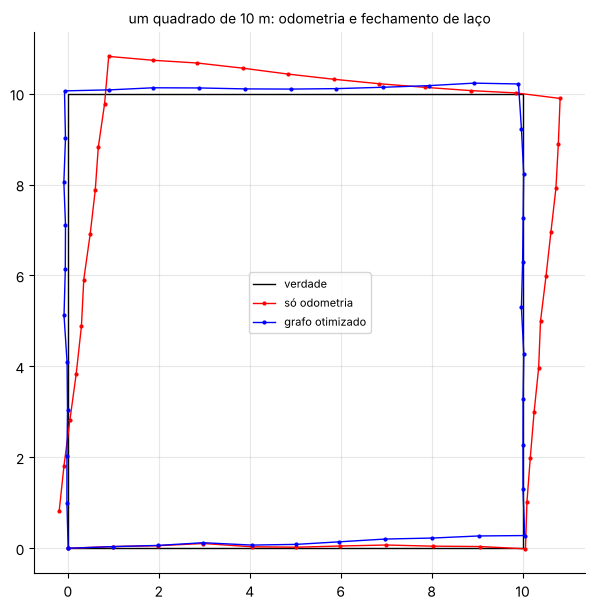

In [3]:
def residuos(poses):
    r = []
    for i, j, Zm, Om in arestas:
        e = Log3(Zm.conj() * poses[i].conj() * poses[j])
        r.append(np.linalg.cholesky(Om).T @ e)          # resíduo "branqueado": a soma dos quadrados já pondera por Ω
    return np.concatenate(r)

def gauss_newton_grafo(poses, n_iter=10, h=1e-6):
    poses = list(poses)
    for it in range(n_iter):
        r0 = residuos(poses)
        J = np.zeros((len(r0), 3 * N))
        for k in range(1, N + 1):                        # a pose 0 fica fixa
            for c_ in range(3):
                d = np.zeros(3); d[c_] = h
                mais, menos = list(poses), list(poses)
                mais[k] = poses[k] * Exp3(d); menos[k] = poses[k] * Exp3(-d)
                J[:, 3 * (k - 1) + c_] = (residuos(mais) - residuos(menos)) / (2 * h)
        delta = np.linalg.lstsq(J, -r0, rcond=None)[0]
        poses = [poses[0]] + [poses[k] * Exp3(delta[3 * (k - 1):3 * k]) for k in range(1, N + 1)]
        print(f"iteração {it + 1}: soma dos quadrados {np.sum(r0**2):12.2f} → {np.sum(residuos(poses)**2):10.2f};  |δ| = {np.linalg.norm(delta):.2e}")
        if np.linalg.norm(delta) < 1e-6:          # abaixo disso, é o ruído das diferenças finitas
            break
    return poses

otimizado = gauss_newton_grafo(odometria)
erro = lambda est: np.array([abs(translacao(est[k]) - translacao(verdade[k])) for k in range(N + 1)])
print(f"\nerro de posição (contra a verdade):  odometria, máximo {erro(odometria).max():.2f} m;  grafo otimizado, máximo {erro(otimizado).max():.3f} m")
gl = len(residuos(otimizado)) - 3 * N
print(f"soma dos quadrados final: {np.sum(residuos(otimizado)**2):.1f}, para {gl} graus de liberdade (o esperado é perto disso)")
confere("o fechamento de laço é respeitado", Log3(Z_laco.conj() * otimizado[0].conj() * otimizado[N]) / SIG_LACO, np.zeros(3), tol=3)
e_odo, e_opt = erro(odometria), erro(otimizado)
print(f"na última pose: odometria {e_odo[-1]:.2f} m, otimizado {e_opt[-1]:.3f} m;  o pior erro otimizado fica na pose {e_opt.argmax()} (de {N})")
confere("o fechamento de laço leva o erro da última pose a poucos centímetros", e_opt[-1] < 0.05, True)
confere("a otimização reduz o pior erro do caminho", e_opt.max() < e_odo.max() / 2, True)

fig, ax = plt.subplots(figsize=(6.5, 6.2))
for nome, cam, est in [("verdade", verdade, "k-"), ("só odometria", odometria, "r.-"), ("grafo otimizado", otimizado, "b.-")]:
    pts = np.array([translacao(q) for q in cam])
    ax.plot(pts.real, pts.imag, est, ms=4, lw=1, label=nome)
ax.set_aspect("equal"); ax.legend(fontsize=8); ax.set_title("um quadrado de 10 m: odometria e fechamento de laço", fontsize=10)
plt.tight_layout(); plt.show()

**Leitura.** Só com a odometria, o caminho estimado se abre: termina a 84 cm do ponto de partida, e o pior ponto dele fica a 1,2 m da verdade. Com o fechamento de laço, o Gauss–Newton no grupo cai, na primeira iteração, de uma soma dos quadrados de quase 9 mil para 2, e converge na segunda; as seguintes só mexem no ruído das diferenças finitas. A soma final, 2,0, é compatível com os 3 graus de liberdade que sobram (o fechamento de laço é a única medida redundante: 41 medidas de 3 componentes para 40 poses livres). A última pose fica a 7 mm da verdade.

Mas o caminho **não** fica perfeito: o pior erro, de 31 cm, está na pose 16, perto do meio da volta. Isso é honesto, e é a lição: um único fechamento de laço diz onde o robô terminou, mas não diz por onde ele passou. O erro que a odometria acumulou até o meio é corrigido só na parte que o laço consegue "ver", e o meio do caminho é o ponto mais distante das duas pontas ancoradas. Para corrigir o meio, são precisos mais fechamentos de laço (passar de novo por um canto, reconhecer um lugar já visitado), e é por isso que robôs de mapeamento revisitam lugares de propósito.

**Para pensar.** Por que não usar um filtro de Kalman? Um filtro corrige a pose **atual** quando chega o fechamento de laço, mas não volta para corrigir as poses passadas (a não ser que as guarde todas no estado, o que é o EKF-SLAM, caro). O grafo de poses guarda tudo e reotimiza. Os sistemas modernos combinam as duas coisas: filtro para o presente, grafo para o passado.

## Exercícios

1. **Jacobiano analítico.** O jacobiano de $\mathrm{Log}(Z^{-1}q_i^{-1}q_j)$ em relação a $\delta_i$ e $\delta_j$ é, em primeira ordem, $-\mathrm{Ad}_{q_j^{-1}q_i}$ e $\mathbf I$. Use-os no lugar das diferenças finitas e compare o tempo.
2. **Matriz esparsa.** Cada aresta envolve só duas poses: o jacobiano é quase todo zero. Monte-o com `scipy.sparse` e resolva com `spsolve`. Até quantas poses o método denso aguenta, e o esparso?
3. **Um fechamento de laço errado.** Troque o fechamento de laço por uma medida errada (o ICP caiu num mínimo local, notebook V(b)). O que acontece com o caminho? Pesquise "M-estimadores" ou "funções de perda robustas" (a perda de Huber) e experimente.